# ¿Nuevo o usado? · El caso de Mercado Libre desde cero
Queremos predecir la condición de una publicación combinando sus pistas: título, precio, vendedor, atributos y logística. Vamos a recorrer el problema completo, desde los archivos hasta los errores y el CSV de Kaggle.
Todos los gráficos usan datos o resultados reales. El mejor CSV previo dio **94,428% en Kaggle público**, informado por el usuario. La meta es 95%; la sección final muestra el estado de la nueva ronda sin convertir una selección en un logro confirmado.

## 1. Clasificación supervisada, sin palabras difíciles
Una fila es una publicación. **X** reúne lo que sabemos de ella; **y** es su condición: `new` o `used`. En train conocemos y y podemos aprender de ejemplos. En test no conocemos y: Kaggle guarda las respuestas.
El primer paso no es elegir un algoritmo. Es comprobar qué datos recibimos y que estén completos.

In [1]:
get_ipython().run_line_magic('matplotlib','inline')
from pathlib import Path
import os,sys,json
import numpy as np
import pandas as pd
ROOT=next((p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/competition_pipeline_v2.py').exists()),None)
if ROOT is None:raise RuntimeError('Abrir desde el repo tp_ap.')
sys.path.insert(0,str(ROOT/'src'))
DATA_DIR=Path(os.getenv('AP2026Q2_DATA_DIR',str(ROOT/'data/ap_2026_q_2/raw')))
OUT=ROOT/'results/round_v2'
from competition_pipeline_v2 import load_data,groups_for
from optimize_leaderboard import split

from case_visuals import *
style()
train,test,audit=load_data(DATA_DIR,OUT)
display(pd.DataFrame(audit)[['filename','expected_rows','valid_rows','complete']])

,filename,expected_rows,valid_rows,complete
0,train_data.jsonlines,70000,70000,True
1,test_data.jsonlines,30000,30000,True


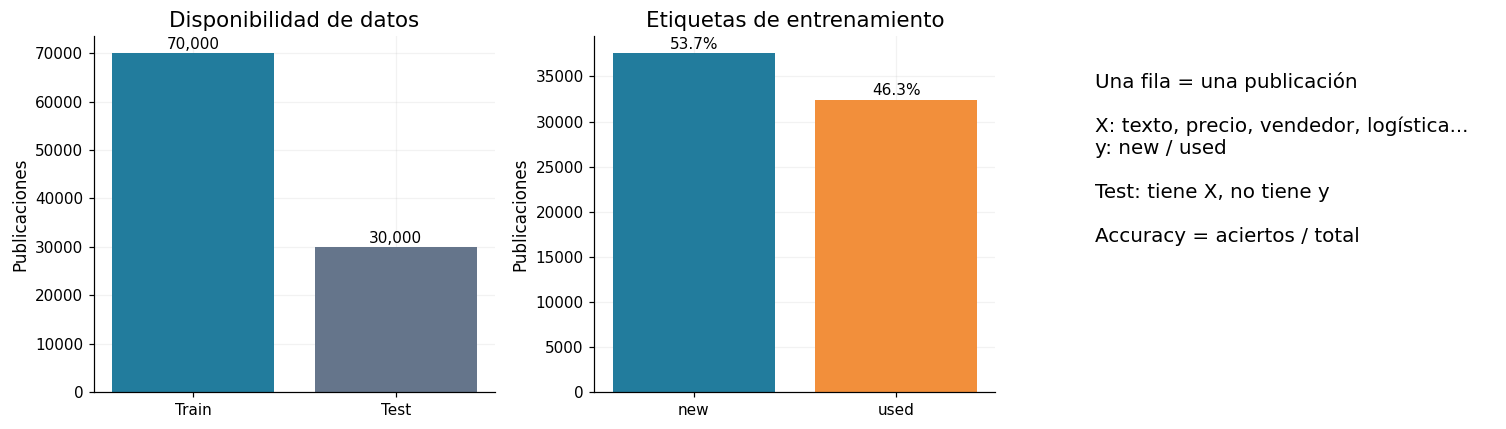

In [2]:
overview(train,test)

**Cómo leerlo:** primero tamaño de los archivos, después frecuencia de clases. Una baseline predice siempre la clase más frecuente. Accuracy de 95% significa cinco errores cada cien ejemplos, aproximadamente; no significa certeza de 95% para cada predicción.

In [3]:
display(train[['title','condition','price','category_id','warranty']].sample(8,random_state=42))
print('Baseline sobre toda la muestra, descriptiva:',train.condition.value_counts(normalize=True).max())

Baseline sobre toda la muestra, descriptiva: 0.5369714285714285


,title,condition,price,category_id,warranty
46730,Pink Floyd - More Cd Nacional Nuevo,new,105.00,MLA15197,"Nuevo, NO cerrado"
48393,Ilíada- Homero (ed. Azulejos) Grecia,used,70.00,MLA41260,None
41416,Curso De Filosofia Por C. Lahr Tomo I,used,41.40,MLA1227,SI
34506,Tacho 139 Led Multicolor Rgb Dmx Dj Luces Y Ef...,new,1599.99,MLA32238,1 AÑO DE GARANTIA TOTAL PRODUCTO NUEVO EN CAJA...
43725,"Alberto Ibáñez Padilla, Una Reina En El Barrio...",used,72.00,MLA41174,Local a la calle
11615,Discusion Sobre El Libre Albedrio - Erasmo,new,226.00,MLA40481,None
24656,Caja Monedero 5 Divisiones Chapa,new,875.00,MLA10093,None
22411,Geografía De Pablo Neruda. Sara Facio. Alicia ...,used,750.00,MLA1198,None


## 2. Una fila puede contener muchas estructuras
Además de números y categorías, hay listas y diccionarios: dirección, envío, atributos, variantes y fotos. Los convertimos en columnas comparables. De envío obtenemos modo y gratuidad; de fotos, cantidad y tamaños; de atributos, marca y otros campos frecuentes.
El texto también ayuda. 'Como nuevo' puede describir un usado; 'sin uso' no obliga a que la etiqueta sea nuevo. Necesitamos combinar información y evaluar errores.

In [4]:
row=train.iloc[0]
display(pd.DataFrame([{'campo':c,'tipo':type(row[c]).__name__,'ejemplo':str(row[c])[:250]} for c in ['title','price','seller_address','shipping','attributes','variations','pictures']]))

,campo,tipo,ejemplo
0,title,str,Pizarron 20x30 + Imagen + Bolsita Artesanal- Y...
1,price,float64,15.02
2,seller_address,dict,"{'country': {'name': 'Argentina', 'id': 'AR'},..."
3,shipping,dict,"{'local_pick_up': True, 'methods': [], 'tags':..."
4,attributes,list,[]
5,variations,list,[]
6,pictures,list,"[{'size': '374x500', 'secure_url': 'https://a2..."


## 3. EDA: mirar antes de modelar
Buscamos faltantes, escalas distintas, categorías asociadas a la condición y pistas del texto. Las siguientes relaciones describen la muestra: no demuestran causalidad.

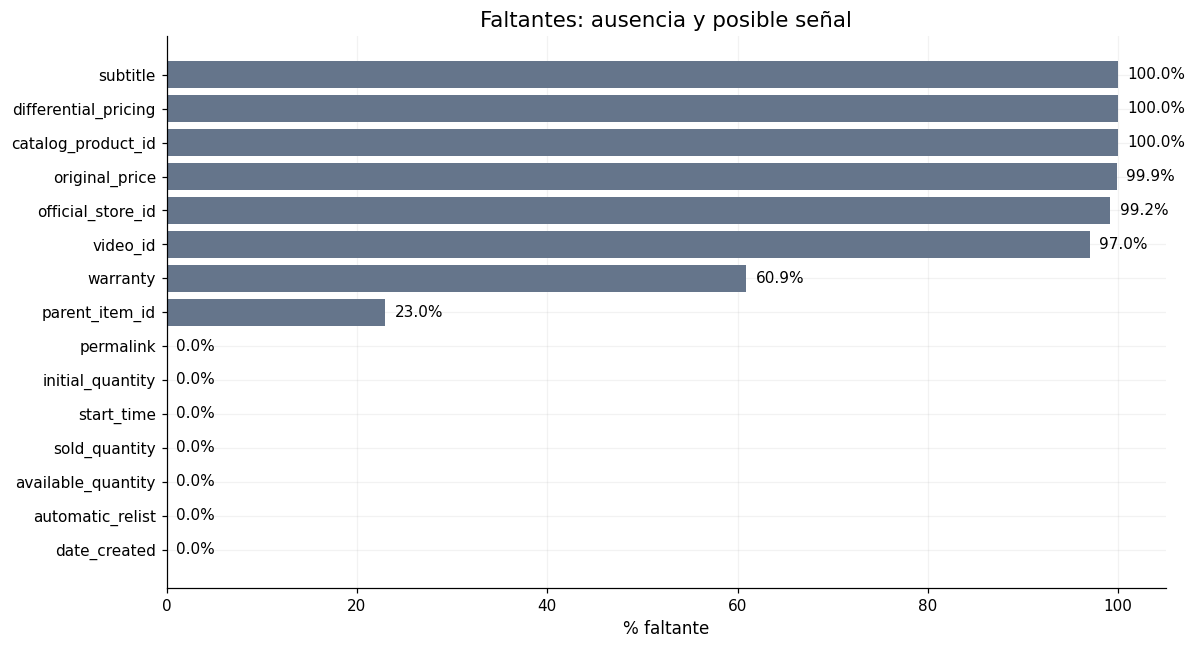

In [5]:
missing(train)

**Faltantes:** ausencia de garantía puede ser informativa. No borramos automáticamente todas esas filas. Conservamos flags de ausencia y categorías desconocidas. Cualquier mediana o regla aprendida debe ajustarse en desarrollo, antes de transformar validación.

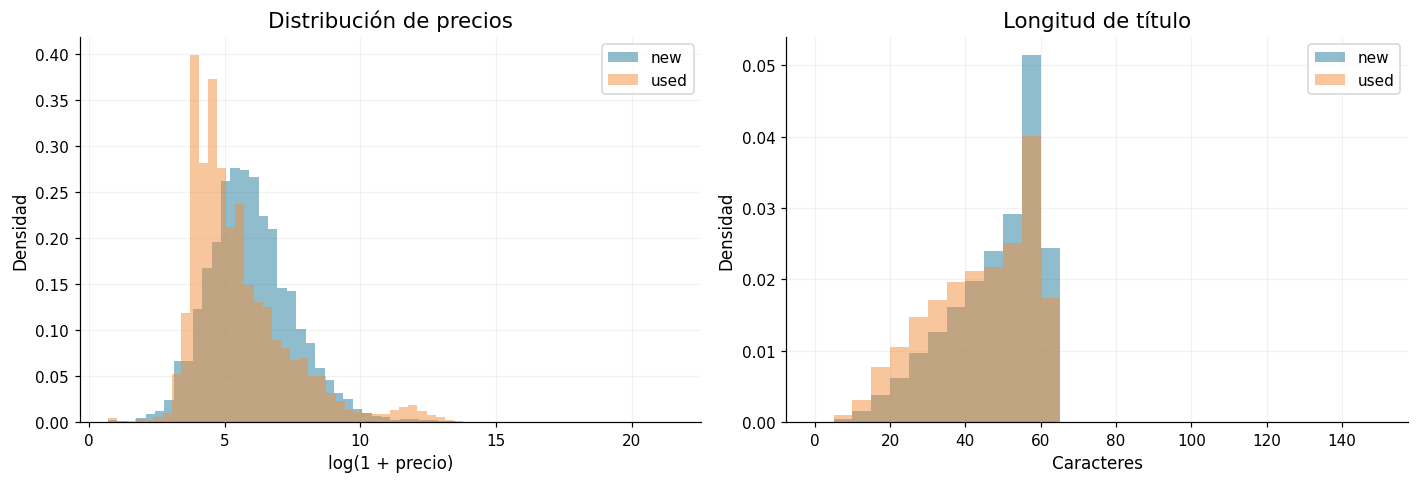

In [6]:
distributions(train)

**Escalas:** usamos log(1 + precio) para observar artículos de valores muy distintos. Un extremo puede ser real; no se elimina solo por distancia estadística. Las distribuciones por condición se solapan, así que precio o longitud de título solos no separan bien el problema.

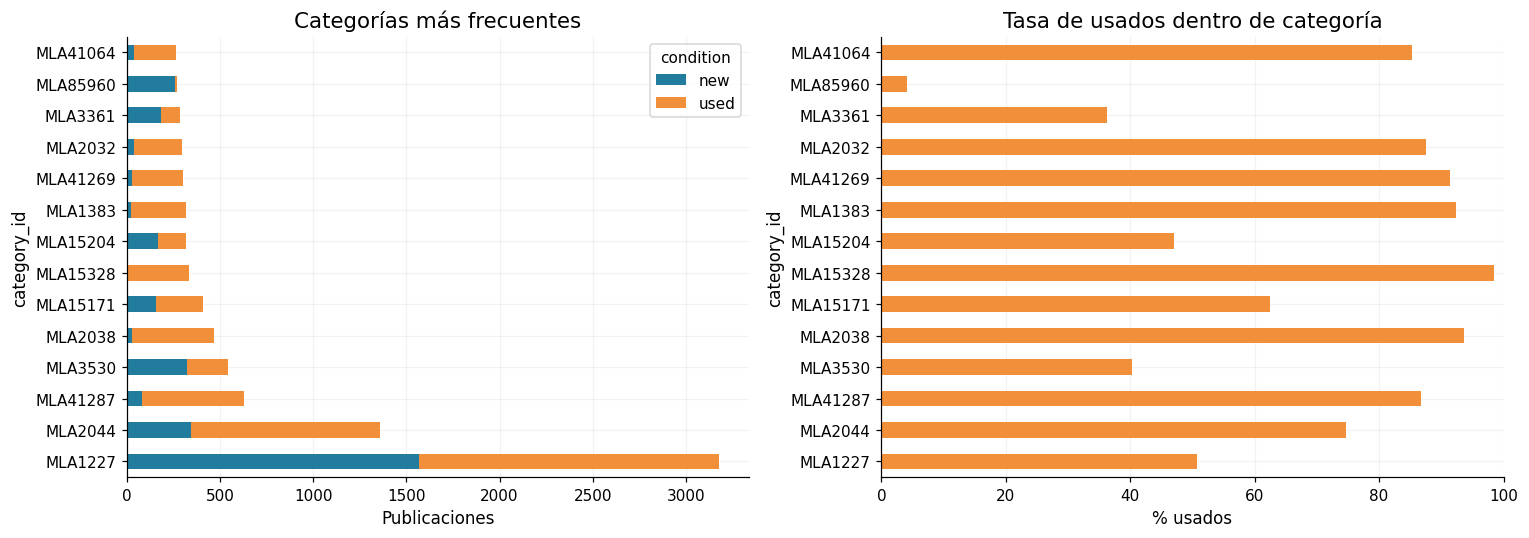

In [7]:
categories(train)

**Contexto:** precio y condición dependen de categoría. Un precio de 10.000 no significa lo mismo para un auto que para un accesorio. Agregamos el precio relativo a la mediana de categoría y vendedor, aprendida en desarrollo.

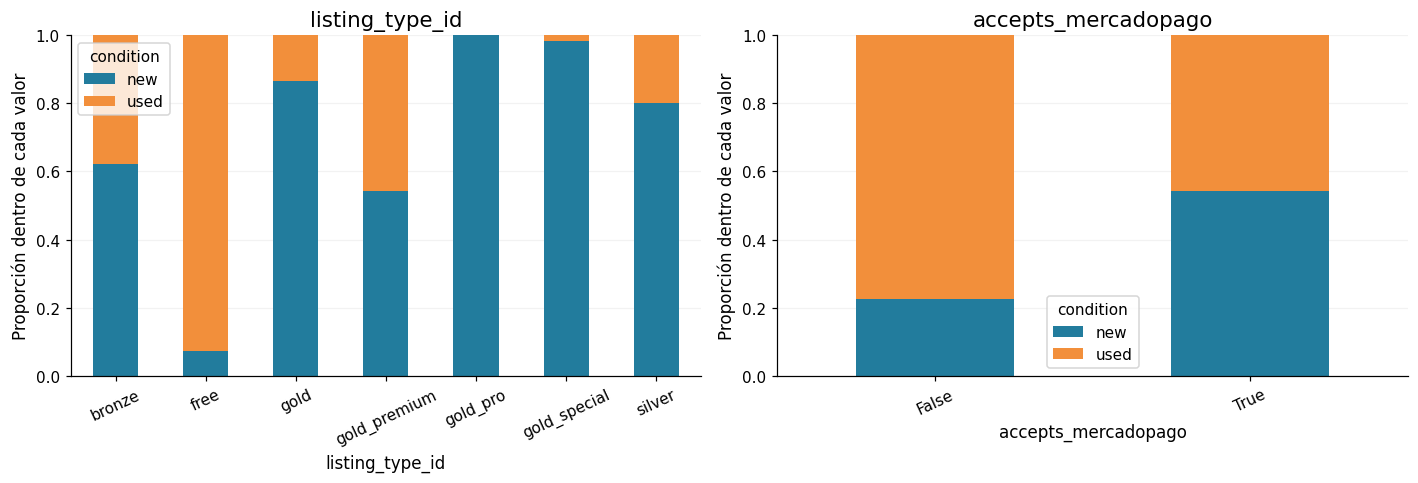

In [8]:
commercial(train)

## 4. Evaluación: aprender reglas, no reconocer al mismo producto
Si una publicación y sus variantes aparecen a ambos lados de un split aleatorio, el modelo puede reconocerlas. Una accuracy alta mediría parcialmente memorización. Por eso agrupamos por `parent_item_id`.
Las familias permanecen juntas. Los vendedores pueden repetirse; evaluar vendedores nuevos requeriría otro protocolo. Ningún split aislado resuelve todas las posibles fugas.

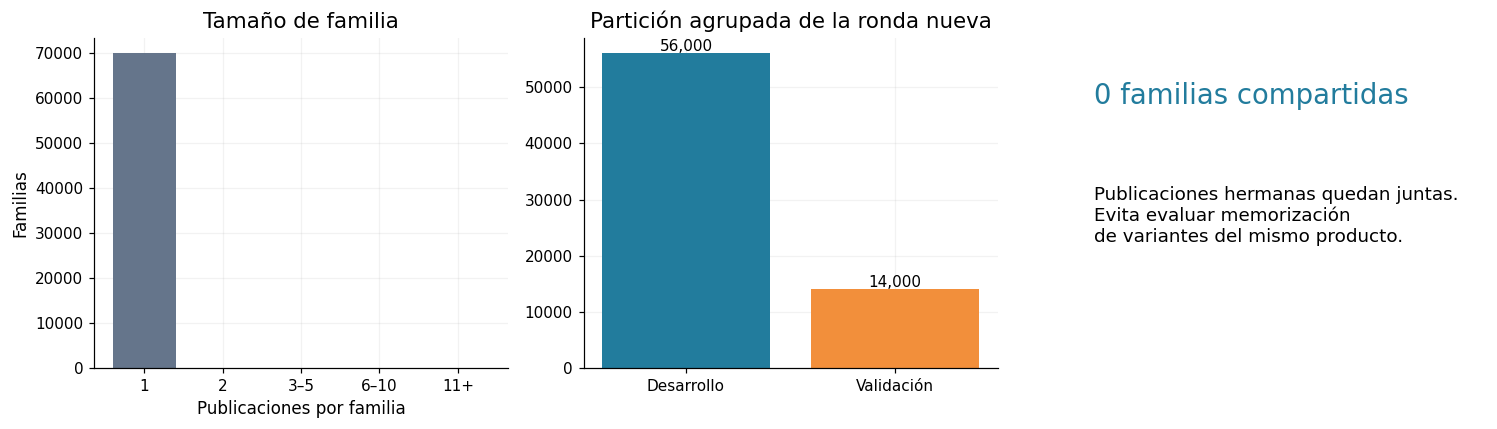

In [9]:
y=(train.condition=='used').to_numpy(dtype='int8');groups=groups_for(train)
t,v=split(y,groups,42,2)
families(train,t,v)

## 5. Feature engineering: convertir pistas en columnas
| Fuente | Ejemplos | Utilidad potencial |
|---|---|---|
| Precio/cantidades | Logs, ratios, diferencias, precio relativo | Forma de comercializar el artículo |
| Título/garantía | Palabras, caracteres, expresiones | Estado declarado y estilo del anuncio |
| Vendedor/categoría | IDs, frecuencias, combinaciones | Contexto |
| JSON anidado | Variantes, fotos, pagos, logística | Estructura de la oferta |
| Atributos | Marca y campos frecuentes | Descripción |
| Ausencias | Indicadores de faltantes | Información no declarada |
El atributo explícito de condición y sus sinónimos se excluyen: incluirlos sería copiar la respuesta.
Este TP clasifica publicaciones existentes. Para predecir al crearlas habría que retirar campos posteriores como ventas acumuladas o ciertos estados.

,señal,n,used_rate
0,Usado / segunda mano,600,0.983333
1,Nuevo / estrenar,3274,0.190898
2,Como nuevo / impecable,782,0.961637
3,Reparar / repuestos,252,0.547619
4,Mayorista / stock,217,0.046083
5,Sin uso / sellado,347,0.351585


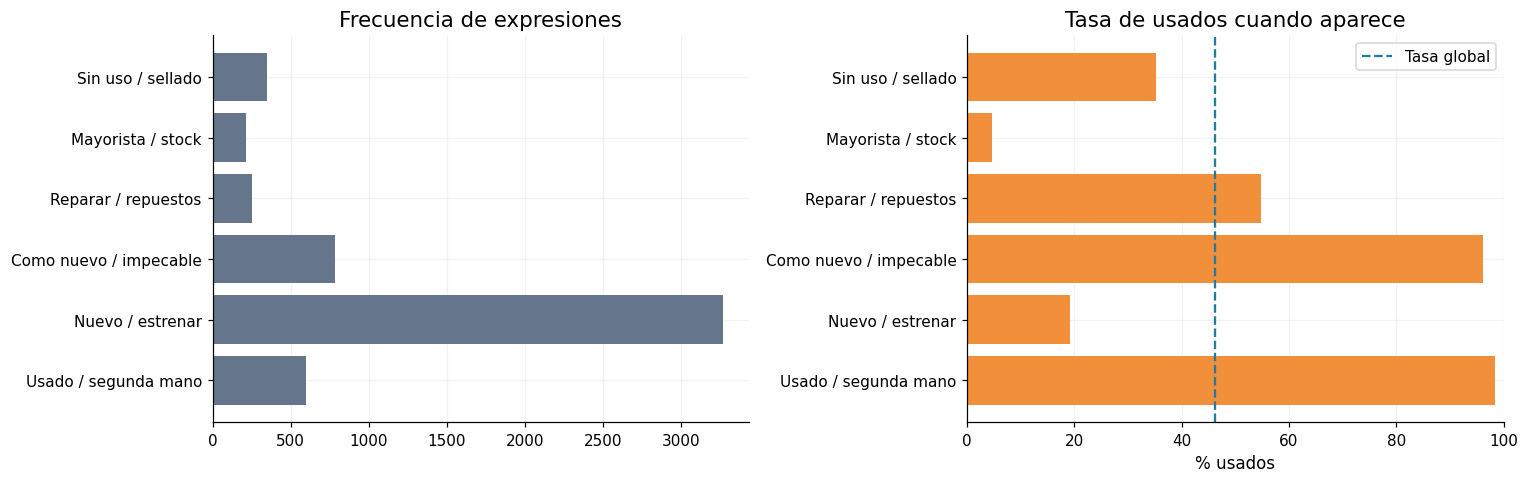

In [10]:
signal_table=signals(train)
display(signal_table)

El primer panel muestra cuántos casos contienen cada expresión; el segundo, qué proporción es usada. Una señal con pocos casos puede parecer perfecta por azar. Estos gráficos son descriptivos. Usar tasas como predictores exige excluir la respuesta de la propia fila.

## 6. Texto a números: TF-IDF, caracteres y SVD
TF-IDF transforma títulos en columnas de términos, con mayor peso para palabras que distinguen documentos. N-gramas de caracteres ayudan con abreviaturas y errores. SVD comprime esas columnas en menos componentes: reduce tamaño, pero pierde algunos detalles.
El siguiente gráfico ajusta una muestra para **ilustrar la representación**; no es el embedding del modelo final ni una métrica de calidad.

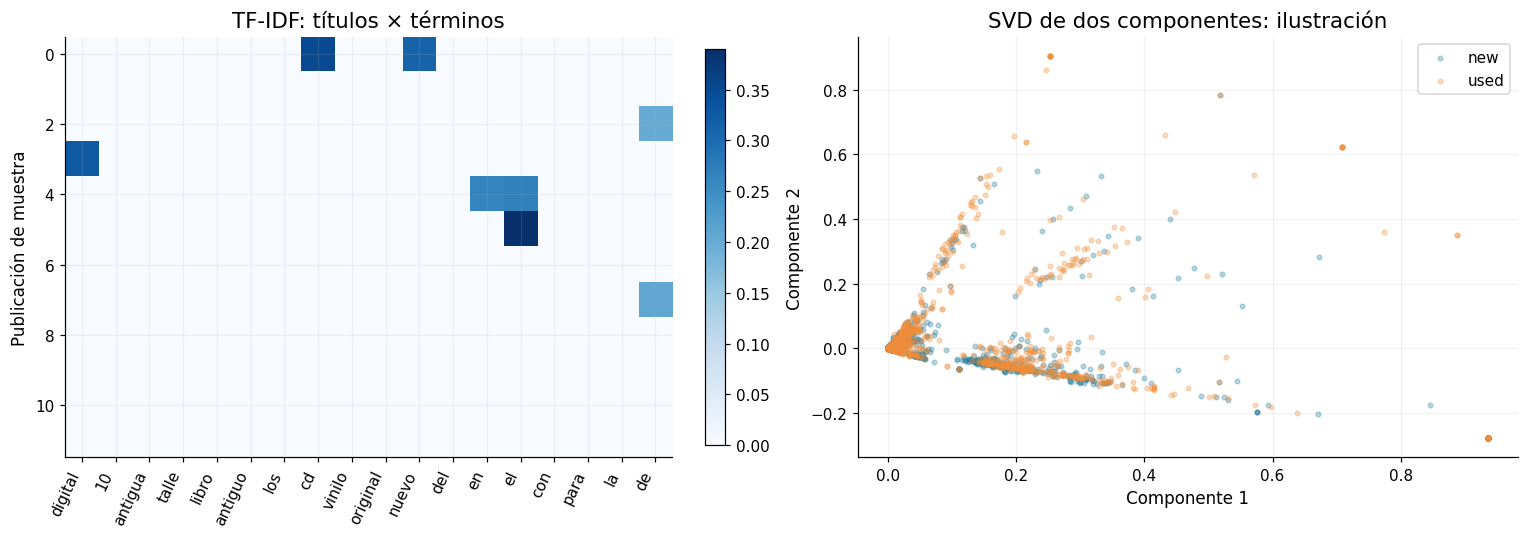

In [11]:
representation(train)

## 7. Modelos: varias formas de aprovechar la misma información
**Logística y SVM:** suman evidencias de miles de términos y categorías; suelen ser fuertes para texto.
**Árboles y boosting:** combinan reglas e interacciones. LightGBM entrena rápido; CatBoost maneja categorías con otro procedimiento.
**Redes:** pueden aprender representaciones flexibles, pero necesitan arquitectura, regularización y representación adecuadas. Las redes previas rindieron por debajo de los árboles; complejidad no garantiza mejora.

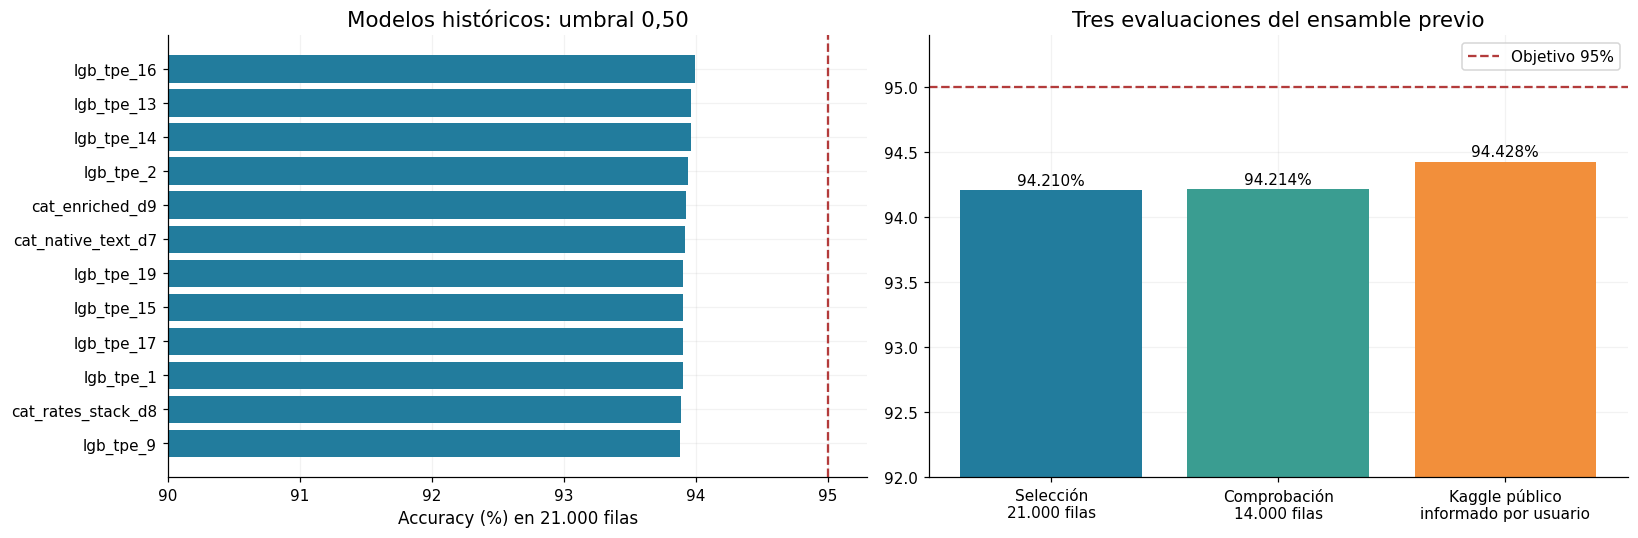

In [12]:
historical(ROOT)

**Comparación:** el panel izquierdo usa el mismo holdout histórico y umbral 0,50. El derecho muestra tres evaluaciones distintas. No sumamos scores ni los confundimos con una evaluación sobre las mismas filas.
En 21.000 filas, tres aciertos adicionales cambian la accuracy solo 0,0143 puntos porcentuales. La refinación fina de pesos encontró una mejora de ese tamaño que no se sostuvo en una comprobación por mitades; por eso se conservó la referencia.

## 8. TPE: elegir configuraciones con la experiencia de ensayos anteriores
Un hiperparámetro decide cómo aprende el modelo: hojas, learning rate, regularización. TPE separa configuraciones buenas y malas, estima distribuciones de ambas y propone puntos con mayor presencia relativa en la región buena.
No conoce la superficie real ni garantiza el óptimo. Puede concentrarse en una zona poco útil. Además, ajustar muchas veces sobre el mismo holdout vuelve optimista el mejor score.

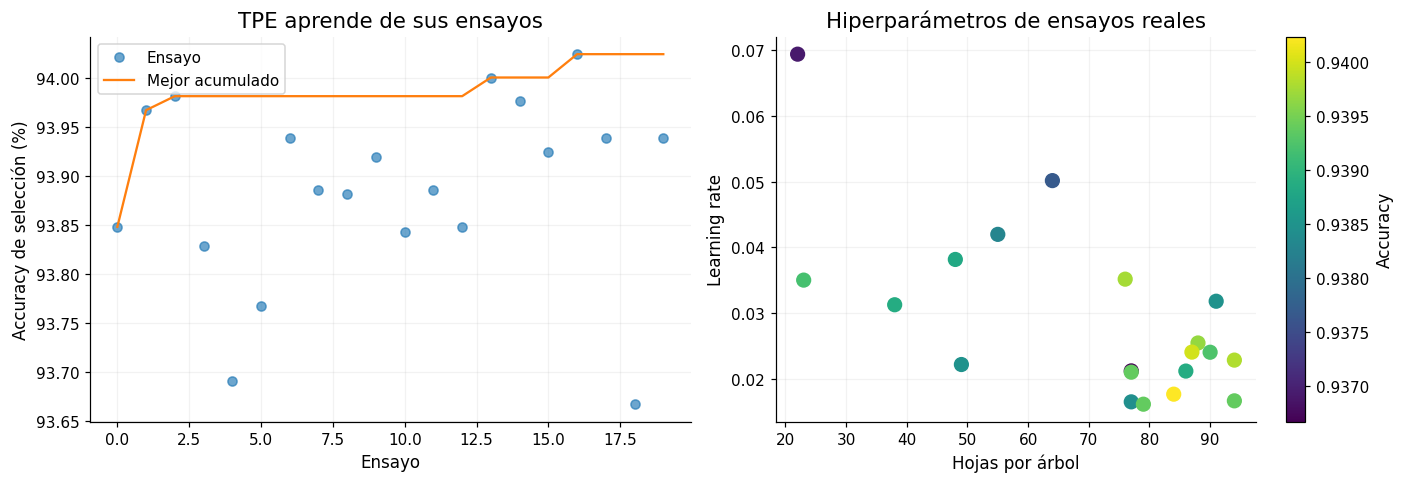

In [13]:
tpe(ROOT)

## 9. Stacking sin copiar respuestas
La nueva ronda usa una predicción de SVM como otra columna para LightGBM. En desarrollo, cada predicción debe venir de un modelo que **no vio la familia de esa fila**.
Se dividen folds internos; se entrena sin uno, se lo predice y se repite. También se refitean vocabulario y TF-IDF en cada fold. Eso es OOF. Para validación, se entrena la SVM en todo desarrollo. Las tasas por vendedor y categoría siguen esa protección.

## 10. Ensamble: combinar probabilidades
El candidato previo mezcla **60% LightGBM + 20% CatBoost profundo + 20% CatBoost con texto nativo**.
Para una publicación, p = 0,6 p_LGB + 0,2 p_Cat9 + 0,2 p_CatTexto. Con p ≥ 0,50 predecimos usado. Los pesos y el umbral se congelan antes de comprobar otro split.
Si los modelos corrigen errores distintos, promediar puede ayudar. Si todos fallan en lo mismo, agregar modelos aporta poco.

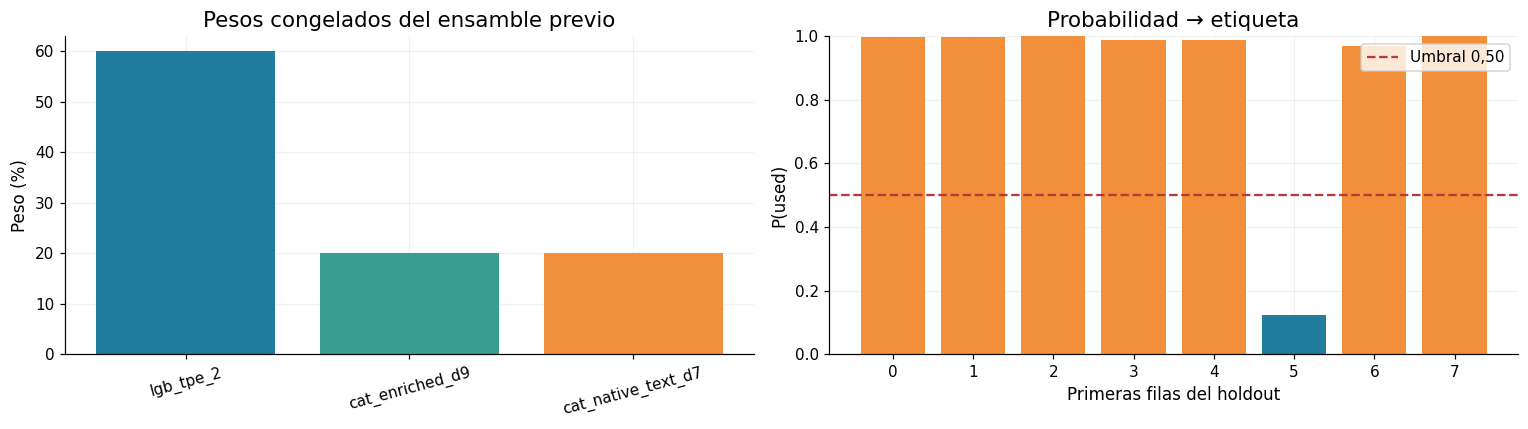

In [14]:
blend(ROOT)

## 11. Evaluación: mirar qué errores cometemos
La matriz distingue nuevos clasificados como usados y usados clasificados como nuevos. ROC muestra ordenamiento a distintos umbrales; precisión-recall se centra en los aciertos y omisiones de used.
Los diagnósticos siguientes usan las probabilidades del **holdout histórico de 21.000 filas**, con umbral congelado 0,50.

/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/sklearn/utils/_plotting.py:176: FutureWarning: `**kwargs` is deprecated and will be removed in 1.9. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(


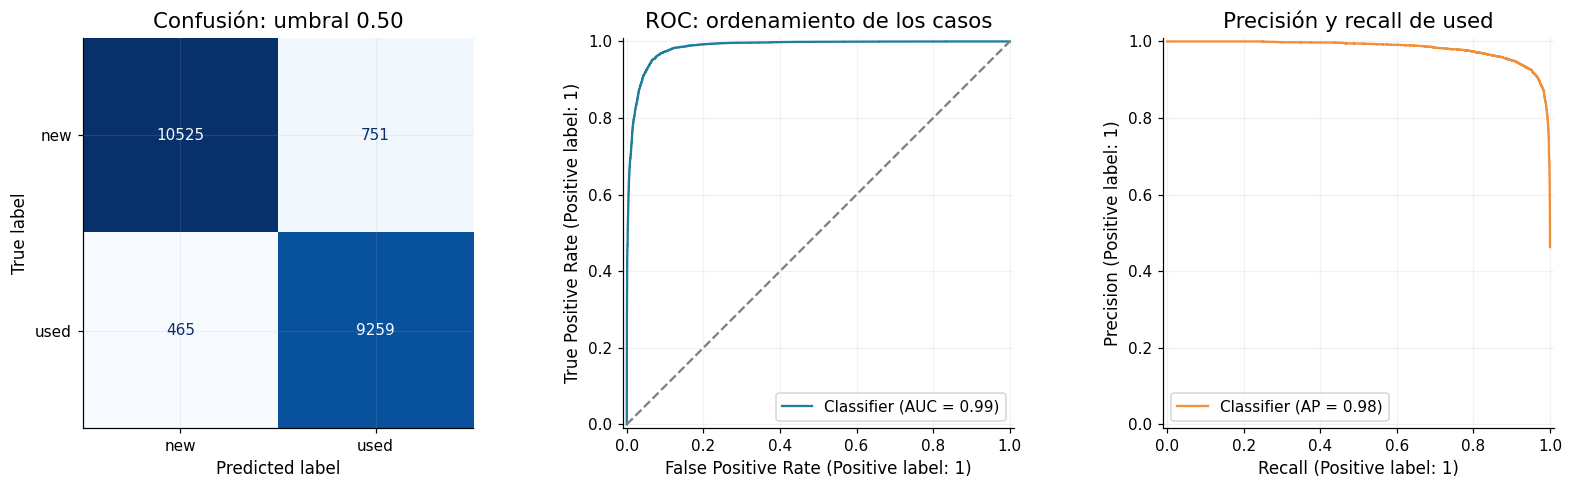

In [15]:
historical_predictions=pd.read_csv(ROOT/'optimization/holdout_predictions.csv')
evaluation(historical_predictions)

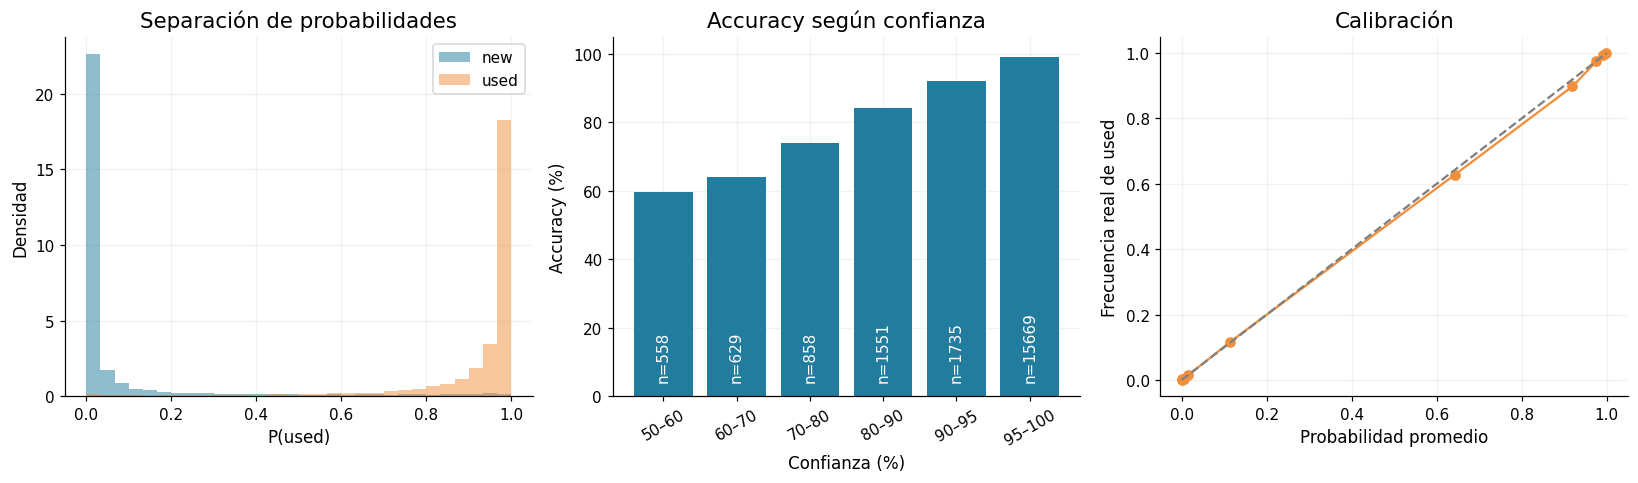

In [16]:
confidence(historical_predictions)

**Confianza:** los casos cerca de 0,50 son ambiguos, pero también puede haber errores con alta confianza. Calibración pregunta si, entre casos con probabilidad estimada 0,80, cerca del 80% son usados. Clasificar bien y calibrar bien no son lo mismo.
Un producto real podría derivar casos ambiguos a revisión humana. Kaggle requiere una etiqueta para todas las filas, por lo que aquí no usamos abstención.

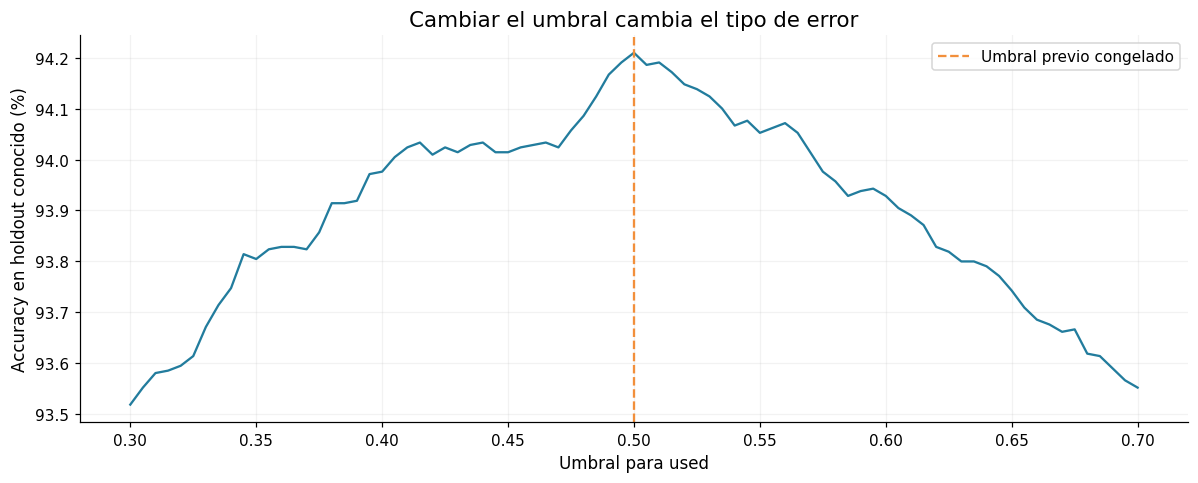

In [17]:
threshold(historical_predictions)

**Umbral:** bajarlo predice más usados y cambia el balance de errores. Buscarlo en el holdout es otro ajuste; debe congelarse antes de la comprobación. Recorrer esta curva ahora no constituye evidencia independiente.

## 12. Publicaciones concretas donde el modelo falla
Unimos probabilidades a las filas originales por índice y comprobamos que coincida la etiqueta antes de mostrar títulos. Así evitamos atribuir errores a registros equivocados.
Cantidad de errores y tasa de error no son lo mismo: una categoría grande puede acumular más errores con una tasa menor.

,title,condition,prob_used,price,category_id
9,Bisel Marco Frontal De Carcasa Lg G Pro E980 E...,used,0.001197,380.0,MLA70369
12,Peavey Express 112 Guitarra Original Usa Perm...,used,0.468717,4300.0,MLA377658
20,Liechtenstein Serie Completa X 4 Sellos Inunda...,new,0.658981,660.0,MLA31961
39,Super Street Fighter 2 Tournament Battle Pila ...,used,0.109457,2800.0,MLA59342
70,Lecciones De Lengua Castellana Ed Jose Moly Li...,new,0.985707,60.0,MLA7772
71,"Dados ,lapicero,adorno,retro!!! Alajero,monede...",used,0.388300,25.0,MLA4335
111,Ventana De Dos Hojas Corredizas De Aluminio,new,0.543532,2700.0,MLA321162
115,"Gothic Rock Box 5 Cds Mission, Cult, Bauhaus, ...",new,0.790888,850.0,MLA15188
133,Frente De Termostato Y Luz De Heladera Con Fre...,used,0.446081,115.0,MLA81240
156,Memoria Micro Sd 4gb Kingston Original Clase 4...,used,0.335207,72.0,MLA13902


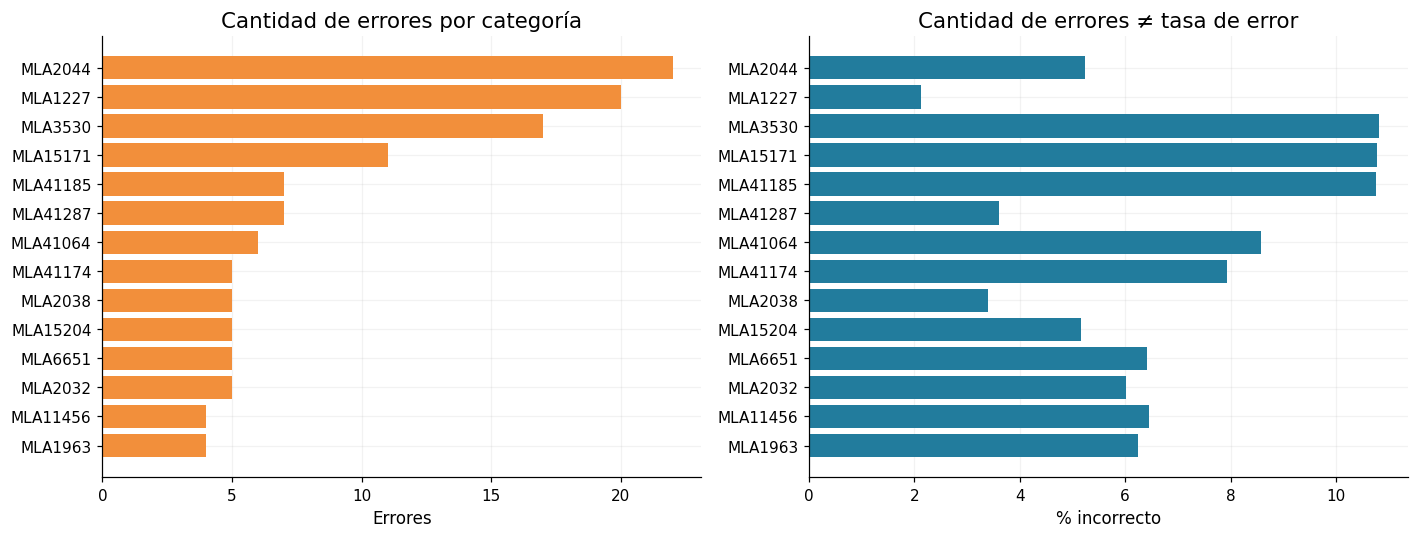

In [18]:
assert (historical_predictions.row_index<len(train)).all()
labels=(train.iloc[historical_predictions.row_index.to_numpy()].condition=='used').to_numpy(dtype='int8')
assert (labels==historical_predictions.y_used.to_numpy()).all(),'El orden de filas difiere; no unir títulos.'
error_examples=errors(train,historical_predictions)
display(error_examples[['title','condition','prob_used','price','category_id']].head(12))

## 13. Nueva ronda: texto complementario y contexto
Se amplían atributos, se agregan comparaciones de precio, expresiones del título y SVM OOF; TPE explora LightGBM y combinaciones de configuraciones.
La selección nueva usa 80/20 en semilla 42. La comprobación usa la semilla 731 y el mismo protocolo que la comprobación histórica, si el dataset coincide. No hay que comparar ciegamente contra el histórico 70/30.
Una corrida sobre una primera copia local incompleta fue interrumpida por reinicio del entorno. Su 94,38% preliminar no se toma como mejora confirmada. La ronda siguiente usa el ZIP íntegro auditado.

,name,accuracy,balanced_accuracy,macro_f1,logloss,threshold,seconds
2,lgb_context_svm_tpe_1,0.939286,0.939972,0.939064,0.155294,0.485,16.569618
10,lgb_context_svm_tpe_9,0.939214,0.939905,0.938993,0.156424,0.485,27.796980
7,lgb_context_svm_tpe_6,0.938857,0.938988,0.938575,0.155462,0.540,15.773928
9,lgb_context_svm_tpe_8,0.938500,0.938890,0.938245,0.156154,0.515,9.599591
3,lgb_context_svm_tpe_2,0.938429,0.939323,0.938225,0.157979,0.460,29.090608
1,lgb_context_svm_tpe_0,0.938286,0.938414,0.938001,0.158698,0.540,17.637992
8,lgb_context_svm_tpe_7,0.938071,0.938916,0.937862,0.158259,0.460,15.064497
0,lgb_context_svm_base,0.937571,0.938386,0.937358,0.159605,0.460,20.491973
6,lgb_context_svm_tpe_5,0.937571,0.938333,0.937352,0.160797,0.480,10.264454
5,lgb_context_svm_tpe_4,0.937071,0.937857,0.936853,0.159898,0.475,20.479102


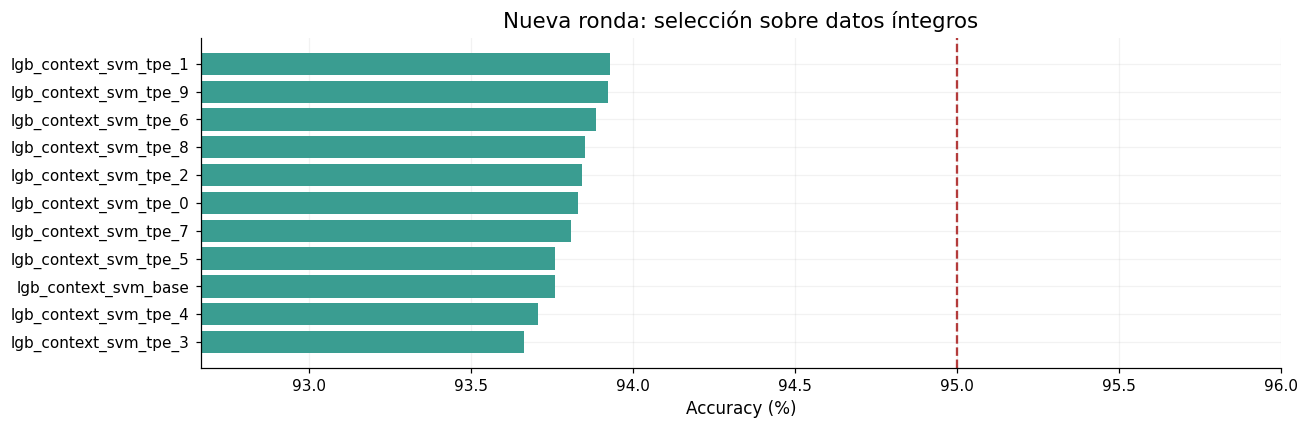

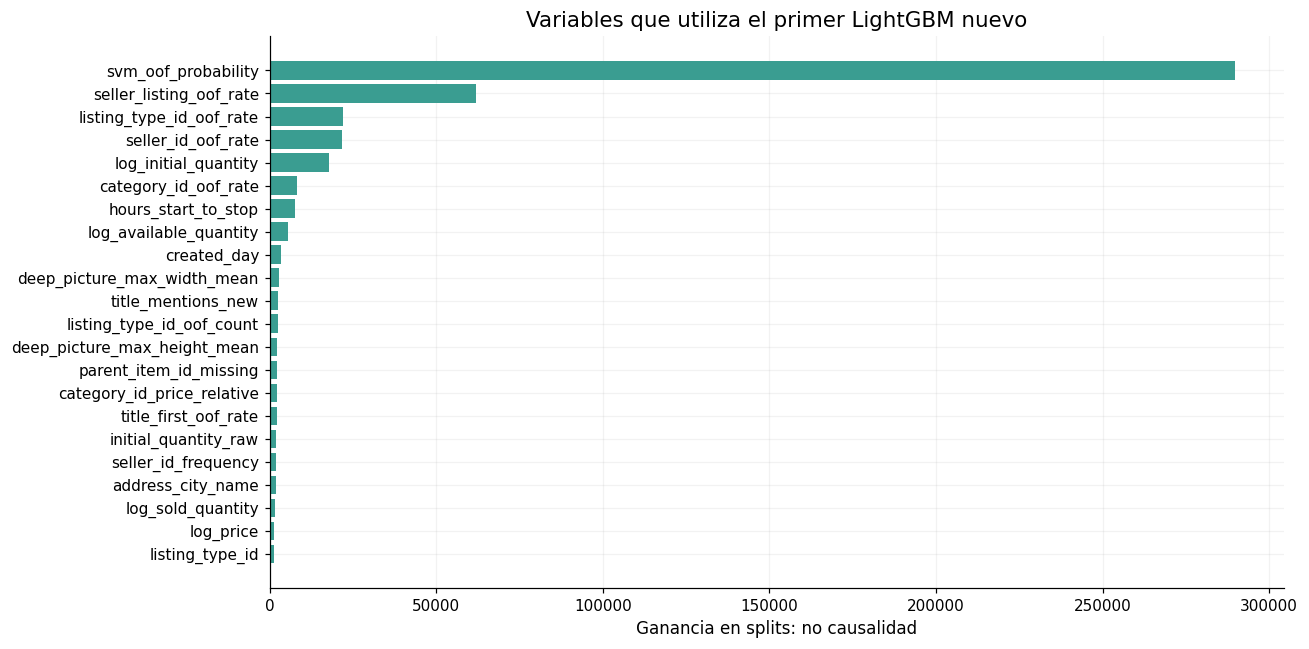

In [19]:
new_table=new_results(OUT)
if new_table is not None:display(new_table.sort_values('accuracy',ascending=False))
importance(OUT)
if (OUT/'selected.json').exists():display(json.loads((OUT/'selected.json').read_text()))

## 14. La submission: el producto final del pipeline
Se refitean las representaciones sobre las 70.000 filas y se reentrenan los componentes elegidos. El test mantiene su orden original. El CSV tiene `ID` de 1 a 30000 y `condition` new/used.
El notebook exporta localmente; no envía a Kaggle. El leaderboard público usa parte del test y el privado puede dar otro resultado. El 94,428% previo es un resultado público informado por el usuario.

,ID,condition
0,1,used
1,2,new
2,3,used
3,4,used
4,5,new
5,6,used
6,7,used
7,8,new
8,9,new
9,10,new


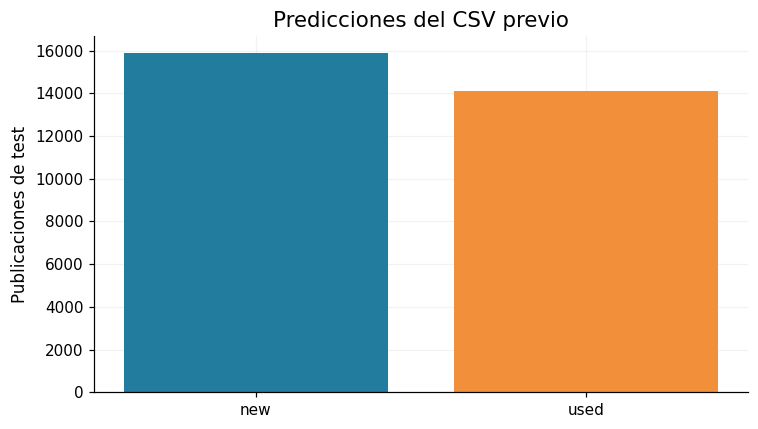

In [20]:
submission=pd.read_csv(ROOT/'submissions/submission_optimized_ensemble.csv')
assert len(submission)==30000 and submission.ID.tolist()==list(range(1,30001))
display(submission.head(10))
fig,ax=plt.subplots(figsize=(7,4));values=submission.condition.value_counts().reindex(['new','used']);ax.bar(values.index,values,color=list(COLORS.values()));ax.set(title='Predicciones del CSV previo',ylabel='Publicaciones de test');show(fig)

## 15. Cómo contárselo a alguien que no conoce el caso
1. Empezar por una publicación concreta y las dos etiquetas posibles.
2. Mostrar qué información hay y cómo se convierte en variables.
3. Explicar por qué las familias permanecen juntas al evaluar.
4. Comparar modelos en el mismo protocolo y justificar el ensamble.
5. Mostrar errores concretos y los límites de los scores.
6. Terminar con la submission y el estado real del objetivo.
El rendimiento provino de combinar texto, estructura y contexto con controles de fuga. El 95% es el objetivo; se declara logrado solo cuando las evidencias guardadas lo sostienen.

## 16. Cinco hipótesis nuevas: intentar mejorar con información complementaria

| Hipótesis | Intuición | Evaluación |
|---|---|---|
| Normalizar texto | `s/uso` y `sin uso` deberían compartir señal | Texto original, normalizado y flags separados |
| Embeddings de títulos | Un modelo preentrenado puede captar significado y sinónimos |384 números por título; solo título y combinado con tabular |
| Imágenes | Embalaje y desgaste podrían ser informativos | Primero comprobar acceso real a las fotos |
| Especialistas | Las señales pueden cambiar entre categorías | Modelos generales más expertos, con fallback |
| Stacking aprendido | Los modelos pueden cometer errores distintos | Regresión logística sobre predicciones OOF estrictas |

Los hiperparámetros se eligen con selección42. Después se congelan y se verifican con731; ambas particiones provienen del mismo conjunto y no garantizan el score público. La misma evaluación se reutilizó en rondas anteriores.

**Cierre:** esta sesión se interrumpió. El último checkpoint guarda57 métricas; la mejor búsqueda conjunta quedó en94,0571% de selección, sin confirmación. Se conserva94,428% como referencia pública. Los capítulos anteriores conservan sus salidas históricas; este apéndice se ejecutó tras la recuperación.

,name,family,accuracy,threshold
25,combined_normstack_0,combined,0.940571,0.525
31,combined_normstack_6,combined,0.940571,0.535
27,combined_normstack_2,combined,0.940500,0.500
33,combined_normstack_8,combined,0.940500,0.510
34,combined_normstack_9,combined,0.940500,0.515
26,combined_normstack_1,combined,0.940429,0.530
32,combined_normstack_7,combined,0.940357,0.505
35,combined_normstack_10,combined,0.940357,0.465
39,combined_stackbase_2,combined,0.940357,0.485
41,normalize_lgb_domain_1,normalize,0.940357,0.465


,family,name,accuracy,threshold
48,stacking,stacking_base_lgb_structured_rates,0.938643,0.535
5,category,category_cluster_8_w0.5,0.939643,0.540
41,normalize,normalize_lgb_domain_1,0.940357,0.465
31,combined,combined_normstack_6,0.940571,0.535


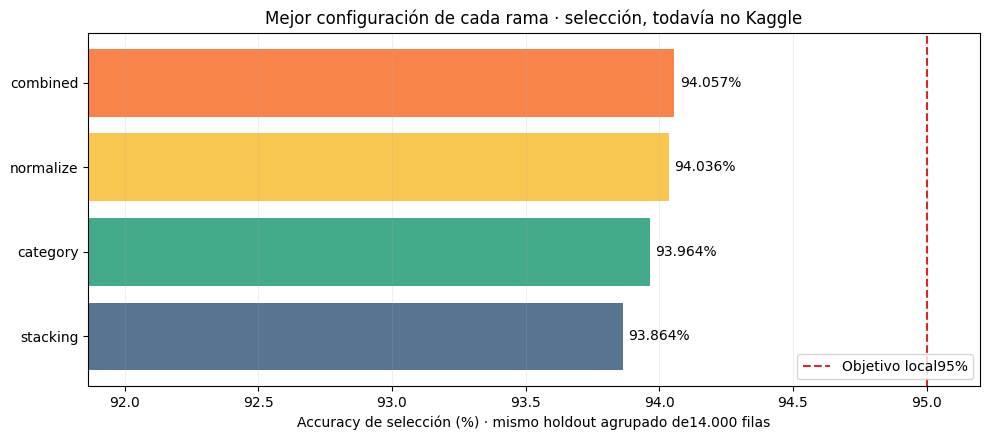

In [2]:
OUT3=ROOT/'results/round_v3'
from round3_visuals import summarize,overview,ablations,embedding_atlas,frozen_evaluation
round3_table=summarize(OUT3)
display(round3_table[[c for c in ['name','family','accuracy','threshold'] if c in round3_table]].head(15))
display(overview(OUT3))

**Interpretación:** estas barras comparan selección local sobre las mismas14.000 filas. No son puntajes de Kaggle. Buscar muchas configuraciones puede mejorar esta tabla por azar: por eso importa la confirmación congelada, el análisis de errores y conservar la referencia anterior.

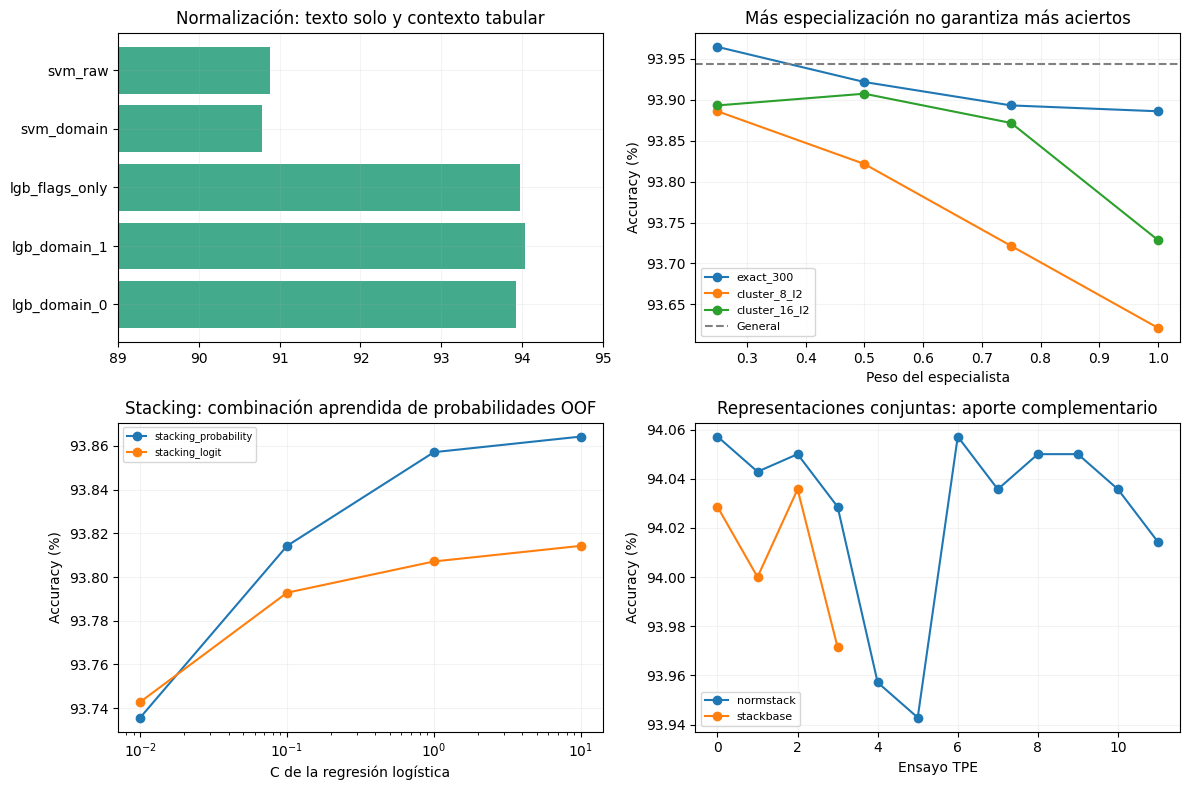

In [3]:
ablations(OUT3)

**Qué aprendemos:** normalizar puede borrar detalles útiles; aumentar el peso de un experto puede empeorar; un meta-modelo no crea información que sus bases no contienen. Los ensayos TPE combinan las nuevas señales sin utilizar probabilidades de entrenamiento del propio ejemplo: cada predicción usada como variable proviene de un modelo que excluyó su familia.

En especialistas, la diferencia de3 aciertos incorpora cambiar el umbral. Con umbral .495 fijo, el experto exacto empata al general; no es evidencia de ganancia por especialización.

In [4]:
embedding_atlas(OUT3)

Regenerar el cache de embeddings para visualizar el espacio.


**Embeddings:** cada punto representa un título, calculado localmente con pesos públicos preentrenados. La proyección2D permite mirar el espacio, pero no conserva toda la información ni implica separación perfecta. Las primeras ejecuciones con ONNX Runtime fueron bloqueadas por telemetría; se utilizó otro backend local. Las imágenes devolvieron403: se documenta el bloqueo, sin presentarlo como un modelo visual evaluado.

Confirmación congelada todavía pendiente.
Mejor público previamente informado:94.428%; cualquier CSV nuevo necesita evaluación en Kaggle.


None

{'names': ['category_cluster_8_w0.5', 'prior_ensemble'],
 'weights': [0.5, 0.5],
 'threshold': 0.48,
 'accuracy': 0.9407142857142857,
 'confirmation': None,
 'prior_confirmation': None,
 'promote_over_previous': False,
 'goal_met_local': False,
 'submission': None}

{'status': 'interrupted_closed_from_durable_checkpoint',
 'original_deadline_utc': '2026-10-11T00:43:51.416Z',
 'closed_utc': '2026-10-11T01:03:53.263822+00:00',
 'last_durable_commit': 'c3eb04b92633d7c66401eff4f04435ac80085fd4',
 'completed_configurations_with_saved_metrics': 57,
 'best_by_family': [{'family': 'stacking',
   'name': 'stacking_base_lgb_structured_rates',
   'accuracy': 0.9386428571428572},
  {'family': 'category',
   'name': 'category_cluster_8_w0.5',
   'accuracy': 0.9396428571428572},
  {'family': 'normalize',
   'name': 'normalize_lgb_domain_1',
   'accuracy': 0.9403571428571428},
  {'family': 'combined',
   'name': 'combined_normstack_6',
   'accuracy': 0.9405714285714286}],
 'stacking_confirmation': {'accuracy': 0.9401428571428572,
  'balanced_accuracy': 0.9403872750036342,
  'macro_f1': 0.9398786964045123,
  'logloss': 0.16930350287289656,
  'threshold': 0.46},
 'prior_confirmation_accuracy': 0.9421428571428572,
 'public_reference_user_report': 0.94428,
 'goal_me

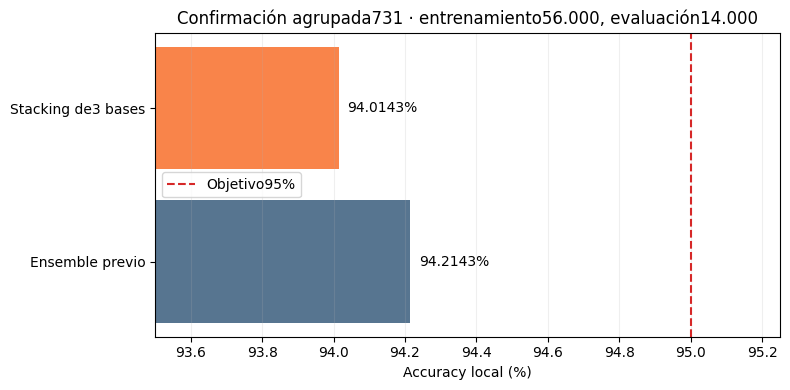

In [5]:
display(frozen_evaluation(OUT3))
if (OUT3/'round3_selected.json').exists():
    final_round3=json.loads((OUT3/'round3_selected.json').read_text());display({k:final_round3.get(k) for k in ['names','weights','threshold','accuracy','confirmation','prior_confirmation','promote_over_previous','goal_met_local','submission']})
print('Mejor público previamente informado:94.428%; cualquier CSV nuevo necesita evaluación en Kaggle.')
display(json.loads((OUT3/'closure.json').read_text()))
from round3_visuals import confirmation_overview
confirmation_overview(OUT3)

**Cómo cerrar la explicación:** mostrar qué hipótesis se probaron, cuáles aportaron señal, cuántos errores corrigió o introdujo el candidato congelado y qué falta verificar. Un aumento pequeño no debe describirse como garantía de mejora. El resultado público y la confirmación local se reportan por separado. Código, decisiones y resultados quedan en `results/round_v3`; el maestro permite repetir la ronda con un presupuesto global.